<a href="https://colab.research.google.com/github/manveethjain8/Machine_Learning_II/blob/main/bayesian_network_event_likelihood.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estimating Event Likelihood with Bayesian Networks

This notebook:
1. **Reads a dataset** (your CSV, or a built-in synthetic sample if none is provided)
2. **Preprocesses** it (discretizes numeric columns, since discrete Bayesian Networks need categorical data)
3. **Learns the network structure** from the data (Hill-Climb search + BIC score)
4. **Estimates the conditional probability tables** (Bayesian estimation with a BDeu prior)
5. **Runs inference** to get the probability of the target event given evidence
6. **Evaluates** the model on held-out data

> **To use your own data:** edit the *Configuration* cell below (`DATA_PATH`, `TARGET`, `EVENT_VALUE`).

In [2]:
!pip install pgmpy pandas numpy matplotlib networkx scikit-learn
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from pgmpy.estimators import HillClimbSearch, BayesianEstimator
from pgmpy.inference import VariableElimination
try:
    from pgmpy.models import DiscreteBayesianNetwork as BayesNet   # pgmpy >= 1.0
except ImportError:
    from pgmpy.models import BayesianNetwork as BayesNet           # older pgmpy

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score, brier_score_loss, confusion_matrix

np.random.seed(42)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 20.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pgmpy]


## 1. Configuration

In [3]:
DATA_PATH   = "data.csv"       # path to your CSV file
TARGET      = "HeartDisease"   # column holding the event you want to predict
EVENT_VALUE = "Yes"            # the value of TARGET that counts as "the event occurred"

N_BINS         = 3             # bins for continuous columns
MAX_UNIQUE_CAT = 10            # numeric columns with <= this many unique values are treated as categorical
MAX_INDEGREE   = 3             # limit parents per node (keeps CPTs small / reliable)
TEST_SIZE      = 0.25
EQUIVALENT_SAMPLE_SIZE = 10    # strength of the BDeu prior (smoothing)

## 2. Load the data
If `DATA_PATH` doesn't exist, a **synthetic patient dataset** is generated so the notebook runs end-to-end.
The synthetic data has a known causal structure (Age, Smoking, Exercise → BMI → BloodPressure/Cholesterol → HeartDisease).

In [4]:
def make_sample_data(n=5000, seed=0):
    rng = np.random.default_rng(seed)
    age      = rng.choice(["Young", "Middle", "Senior"], n, p=[0.3, 0.4, 0.3])
    smoking  = rng.random(n) < np.where(age == "Young", 0.25, 0.2)
    exercise = rng.random(n) < np.where(age == "Senior", 0.35, 0.55)
    bmi_p = 0.25 + 0.25*(~exercise) + 0.10*(age == "Senior")
    bmi   = np.where(rng.random(n) < bmi_p, "High", "Normal")
    bp_p  = 0.15 + 0.30*(bmi == "High") + 0.15*(age == "Senior") + 0.10*smoking
    bp    = np.where(rng.random(n) < bp_p, "High", "Normal")
    chol_p = 0.15 + 0.35*(bmi == "High") + 0.10*(age != "Young")
    chol   = np.where(rng.random(n) < chol_p, "High", "Normal")
    hd_p = (0.03 + 0.20*(bp == "High") + 0.15*(chol == "High")
            + 0.15*smoking + 0.07*(age == "Senior"))
    hd = np.where(rng.random(n) < np.clip(hd_p, 0, 0.95), "Yes", "No")
    return pd.DataFrame({"Age": age, "Smoking": np.where(smoking, "Yes", "No"),
                         "Exercise": np.where(exercise, "Yes", "No"), "BMI": bmi,
                         "BloodPressure": bp, "Cholesterol": chol, "HeartDisease": hd})

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded {DATA_PATH}")
else:
    print(f"'{DATA_PATH}' not found -> using synthetic sample data (target='HeartDisease').")
    df = make_sample_data()
    TARGET, EVENT_VALUE = "HeartDisease", "Yes"

print(df.shape)
df.head()

'data.csv' not found -> using synthetic sample data (target='HeartDisease').
(5000, 7)


,Age,Smoking,Exercise,BMI,BloodPressure,Cholesterol,HeartDisease
0,Middle,No,No,High,Normal,High,No
1,Young,No,No,High,Normal,Normal,No
2,Young,No,No,Normal,Normal,Normal,No
3,Young,No,No,Normal,Normal,Normal,No
4,Senior,No,No,High,Normal,Normal,No


In [5]:
print(df.dtypes, "\n")
print("Missing values per column:\n", df.isna().sum(), "\n")
print(f"Event rate  P({TARGET}={EVENT_VALUE}) = {(df[TARGET].astype(str) == str(EVENT_VALUE)).mean():.3f}")

Age              object
Smoking          object
Exercise         object
BMI              object
BloodPressure    object
Cholesterol      object
HeartDisease     object
dtype: object 

Missing values per column:
 Age              0
Smoking          0
Exercise         0
BMI              0
BloodPressure    0
Cholesterol      0
HeartDisease     0
dtype: int64 

Event rate  P(HeartDisease=Yes) = 0.215


## 3. Preprocessing
Discrete Bayesian Networks need categorical variables. We drop rows with missing values, quantile-bin continuous columns, and cast everything to string labels.

In [6]:
def preprocess(df, target, n_bins=3, max_unique=10):
    d = df.dropna().copy()
    for col in d.columns:
        if col == target:
            d[col] = d[col].astype(str)
        elif pd.api.types.is_numeric_dtype(d[col]) and d[col].nunique() > max_unique:
            d[col] = pd.qcut(d[col], q=n_bins, duplicates="drop").astype(str)
        else:
            d[col] = d[col].astype(str)
    return d.reset_index(drop=True)

data = preprocess(df, TARGET, N_BINS, MAX_UNIQUE_CAT)
EVENT_VALUE = str(EVENT_VALUE)
assert EVENT_VALUE in data[TARGET].unique(), f"EVENT_VALUE {EVENT_VALUE!r} not found in {TARGET}"

print({c: data[c].nunique() for c in data.columns})
train, test = train_test_split(data, test_size=TEST_SIZE, random_state=42, stratify=data[TARGET])
print(f"\nTrain: {len(train)}  Test: {len(test)}")

{'Age': 3, 'Smoking': 2, 'Exercise': 2, 'BMI': 2, 'BloodPressure': 2, 'Cholesterol': 2, 'HeartDisease': 2}

Train: 3750  Test: 1250


## 4. Structure learning
Hill-climb search over DAGs, scored with BIC (which penalizes complexity). Learned edges represent **conditional dependencies** — they suggest, but don't prove, causal direction.

In [7]:
hc = HillClimbSearch(train)
try:
    dag = hc.estimate(scoring_method="bic-d", max_indegree=MAX_INDEGREE, show_progress=False)
except Exception:
    dag = hc.estimate(scoring_method="bic", max_indegree=MAX_INDEGREE, show_progress=False)

edges = list(dag.edges())
print(f"{len(edges)} edges learned:")
for e in edges: print("  ", e[0], "->", e[1])

9 edges learned:
   Smoking -> HeartDisease
   Smoking -> BloodPressure
   Exercise -> Age
   BMI -> BloodPressure
   BMI -> Exercise
   BloodPressure -> HeartDisease
   BloodPressure -> Age
   Cholesterol -> BMI
   Cholesterol -> HeartDisease


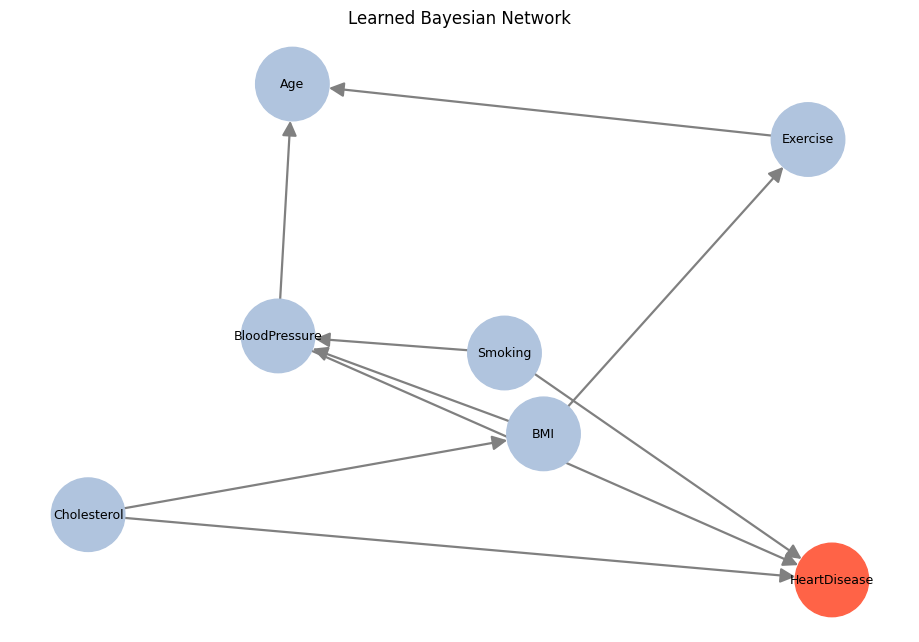

In [8]:
# --- Optional: force domain knowledge instead of (or on top of) learned structure ---
# edges = [("Age","BloodPressure"), ("Smoking","HeartDisease"), ...]
# Use forbidden/required edges in HillClimbSearch.estimate(black_list=[...], white_list=[...], fixed_edges=[...])

def plot_dag(edges, nodes, target):
    G = nx.DiGraph(); G.add_nodes_from(nodes); G.add_edges_from(edges)
    colors = ["tomato" if n == target else "lightsteelblue" for n in G.nodes()]
    plt.figure(figsize=(9, 6))
    pos = nx.spring_layout(G, seed=3, k=1.2)
    nx.draw(G, pos, with_labels=True, node_color=colors, node_size=2800, font_size=9,
            arrowsize=22, edge_color="gray", width=1.6)
    plt.title("Learned Bayesian Network"); plt.show()

plot_dag(edges, list(data.columns), TARGET)

## 5. Parameter estimation
Bayesian estimation with a BDeu prior fills the conditional probability tables (CPTs); the prior avoids zero probabilities for unseen combinations.

In [9]:
model = BayesNet(edges)
model.add_nodes_from(data.columns)          # keep isolated variables too

estimator = BayesianEstimator(model, train)
cpds = [estimator.estimate_cpd(node, prior_type="BDeu",
                               equivalent_sample_size=EQUIVALENT_SAMPLE_SIZE)
        for node in model.nodes()]
model.add_cpds(*cpds)

print("Model valid:", model.check_model())
print(f"\nCPT for the target ({TARGET}):")
print(model.get_cpds(TARGET))

Model valid: True

CPT for the target (HeartDisease):
+-------------------+-----+-----------------------+
| BloodPressure     | ... | BloodPressure(Normal) |
+-------------------+-----+-----------------------+
| Cholesterol       | ... | Cholesterol(Normal)   |
+-------------------+-----+-----------------------+
| Smoking           | ... | Smoking(Yes)          |
+-------------------+-----+-----------------------+
| HeartDisease(No)  | ... | 0.7913077525450274    |
+-------------------+-----+-----------------------+
| HeartDisease(Yes) | ... | 0.20869224745497258   |
+-------------------+-----+-----------------------+


## 6. Inference: likelihood of the event
Exact inference via Variable Elimination. Edit the `evidence` dictionaries to ask your own questions — values must match category labels in the data.

In [10]:
infer = VariableElimination(model)

def p_event(evidence=None):
    q = infer.query([TARGET], evidence=evidence or {}, show_progress=False)
    states = q.state_names[TARGET]
    return float(q.values[states.index(EVENT_VALUE)])

print("Available values per variable:")
for c in data.columns: print(f"  {c}: {sorted(data[c].unique())}")

Available values per variable:
  Age: ['Middle', 'Senior', 'Young']
  Smoking: ['No', 'Yes']
  Exercise: ['No', 'Yes']
  BMI: ['High', 'Normal']
  BloodPressure: ['High', 'Normal']
  Cholesterol: ['High', 'Normal']
  HeartDisease: ['No', 'Yes']


In [11]:
# Example queries - edit to match YOUR columns/values
cols = [c for c in data.columns if c != TARGET]
ex_vals = {c: sorted(data[c].unique()) for c in cols}

scenarios = {
    "Baseline (no evidence)": {},
    f"{cols[0]}={ex_vals[cols[0]][0]}": {cols[0]: ex_vals[cols[0]][0]},
    f"{cols[0]}={ex_vals[cols[0]][-1]}": {cols[0]: ex_vals[cols[0]][-1]},
    f"{cols[0]}={ex_vals[cols[0]][-1]}, {cols[1]}={ex_vals[cols[1]][-1]}":
        {cols[0]: ex_vals[cols[0]][-1], cols[1]: ex_vals[cols[1]][-1]},
}
# Handy defaults for the synthetic sample:
if TARGET == "HeartDisease" and "Smoking" in data.columns and "BloodPressure" in data.columns:
    scenarios["Smoker + High BP + High Cholesterol"] = {"Smoking": "Yes", "BloodPressure": "High", "Cholesterol": "High"}
    scenarios["Non-smoker + Normal BP + Normal Chol"] = {"Smoking": "No", "BloodPressure": "Normal", "Cholesterol": "Normal"}

res = pd.DataFrame({"Evidence": list(scenarios), f"P({TARGET}={EVENT_VALUE})": [p_event(e) for e in scenarios.values()]})
res.style.format({res.columns[1]: "{:.3f}"}).bar(subset=[res.columns[1]], color="#f4a582", vmin=0, vmax=1)

,Evidence,P(HeartDisease=Yes)
0,Baseline (no evidence),0.215
1,Age=Middle,0.197
2,Age=Young,0.198
3,"Age=Young, Smoking=Yes",0.331
4,Smoker + High BP + High Cholesterol,0.520
5,Non-smoker + Normal BP + Normal Chol,0.041


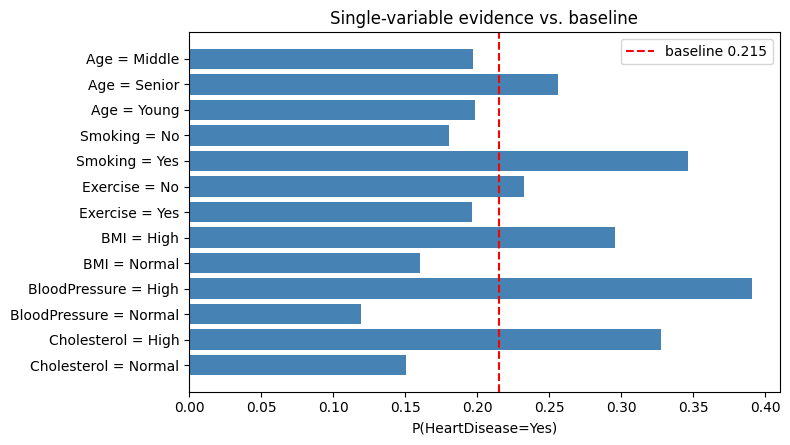

In [12]:
# Which variables influence the event most? Sensitivity of P(event) to each variable's states.
rows = []
for c in cols:
    for v in sorted(data[c].unique()):
        rows.append({"Variable": c, "Value": v, "P(event | value)": p_event({c: v})})
sens = pd.DataFrame(rows)
base = p_event()

fig, ax = plt.subplots(figsize=(8, max(3, 0.35*len(sens))))
labels = sens["Variable"] + " = " + sens["Value"]
ax.barh(labels, sens["P(event | value)"], color="steelblue")
ax.axvline(base, color="red", ls="--", label=f"baseline {base:.3f}")
ax.set_xlabel(f"P({TARGET}={EVENT_VALUE})"); ax.legend(); ax.invert_yaxis()
plt.title("Single-variable evidence vs. baseline"); plt.tight_layout(); plt.show()

## 7. Evaluation on held-out data
We predict P(event | all other observed variables) for each test row and compare with the actual outcome.

In [13]:
probs = model.predict_probability(test.drop(columns=[TARGET]))
p_col = f"{TARGET}_{EVENT_VALUE}"
p_test = probs[p_col].values
y_test = (test[TARGET] == EVENT_VALUE).astype(int).values
y_pred = (p_test >= 0.5).astype(int)

print(f"ROC-AUC     : {roc_auc_score(y_test, p_test):.3f}")
print(f"Brier score : {brier_score_loss(y_test, p_test):.3f}  (lower is better)")
print(f"Accuracy@0.5: {accuracy_score(y_test, y_pred):.3f}  (baseline majority-class: {max(y_test.mean(), 1-y_test.mean()):.3f})")
print("\nConfusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(y_test, y_pred))

ROC-AUC     : 0.742
Brier score : 0.147  (lower is better)
Accuracy@0.5: 0.787  (baseline majority-class: 0.786)

Confusion matrix [[TN FP],[FN TP]]:
 [[962  20]
 [246  22]]


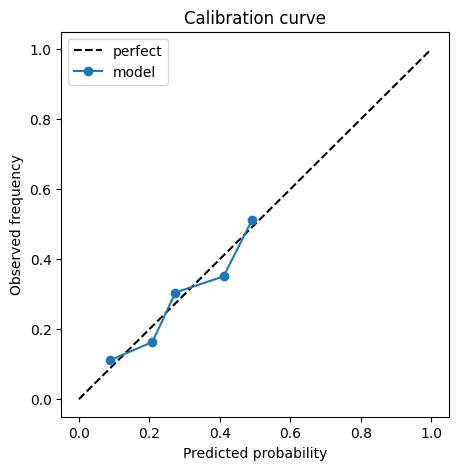

,pred,obs,n
bin,,,
"(0.0399, 0.191]",0.088493,0.111441,673
"(0.191, 0.209]",0.208692,0.163636,110
"(0.209, 0.274]",0.274089,0.304878,164
"(0.274, 0.457]",0.410797,0.351064,188
"(0.457, 0.52]",0.492058,0.513043,115


In [14]:
# Calibration: do predicted probabilities match observed frequencies?
cal = pd.DataFrame({"p": p_test, "y": y_test})
cal["bin"] = pd.qcut(cal["p"], q=min(8, cal["p"].nunique()), duplicates="drop")
g = cal.groupby("bin", observed=True).agg(pred=("p", "mean"), obs=("y", "mean"), n=("y", "size"))

plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], "k--", label="perfect")
plt.plot(g["pred"], g["obs"], "o-", label="model")
plt.xlabel("Predicted probability"); plt.ylabel("Observed frequency")
plt.title("Calibration curve"); plt.legend(); plt.show()
g

## 8. Predict for a new individual
Give any partial set of observations; the network handles missing variables naturally by marginalizing over them.

In [15]:
new_case = {c: ex_vals[c][-1] for c in cols[:3]}   # <- replace with your own observations
print("Evidence:", new_case)
print(f"P({TARGET}={EVENT_VALUE} | evidence) = {p_event(new_case):.3f}")

# Reverse (diagnostic) reasoning: given the event occurred, what do we infer about a cause?
q = infer.query([cols[0]], evidence={TARGET: EVENT_VALUE}, show_progress=False)
print(f"\nP({cols[0]} | {TARGET}={EVENT_VALUE}):\n", q)

Evidence: {'Age': 'Young', 'Smoking': 'Yes', 'Exercise': 'Yes'}
P(HeartDisease=Yes | evidence) = 0.323

P(Age | HeartDisease=Yes):
 +-------------+------------+
| Age         |   phi(Age) |
+=============+============+
| Age(Middle) |     0.3641 |
+-------------+------------+
| Age(Senior) |     0.3553 |
+-------------+------------+
| Age(Young)  |     0.2806 |
+-------------+------------+


## Notes & caveats
- **Structure learning ≠ causation.** Edges reflect statistical dependence; use domain knowledge (`white_list`, `black_list`, `fixed_edges`) to enforce or forbid links.
- **Discretization matters.** Bin counts affect both accuracy and CPT size; try different `N_BINS`.
- **Sparse data:** many parents + many states → huge CPTs. Lower `MAX_INDEGREE` or merge rare categories.
- **Prior strength:** raise `EQUIVALENT_SAMPLE_SIZE` for more smoothing on small datasets.
- Alternatives: `TreeSearch` (Chow-Liu / TAN) or `PC` (constraint-based) for structure learning.